# Visualize Cell Crop Images

In [1]:
import pickle
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import sys
sys.path.insert(1, "../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
sys.path.insert(1, "../1_snakemake_pipeline/2025_varchamp_snakemake/3.downstream_analyses/scripts/cell_img_visualization")
from cell_selector import (
    filter_cells_by_metadata,
    filter_by_quality_metrics,
    select_phenotype_extreme_cells,
    compute_distance_to_edge,
    select_cells_top_n,
    select_cells_percentile_random
)
from cell_cropper import (
    load_multichannel_cell_crops, 
    extract_cell_crop, 
    get_crop_coordinates_bbox,
    load_cell_image,
    validate_and_pad_crop,
    resize
)
from cell_visualizer import (
    viz_cell_grid, 
    viz_cell_single_channel,
    viz_cell_multi_channel,
    plot_cell_comparison,
)

## 1. Loading data

In [2]:
OUT_IMG_DIR = f"../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/visualize_imgs"
# To load the dictionary and DataFrames later
with open("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/visualize_cells/batch_prof_dict.pkl", "rb") as f:
    batch_profiles = pickle.load(f)

# Load profiles
profiles = pl.concat([
    profile for _, profile in batch_profiles.items()
])

profile_feats = pl.read_parquet(
    "../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_all.parquet"
).unique(subset=["Metadata_CellID"], keep="first") ## ref_var_sc_profiles_mad_gfp_filtered, ref_var_sc_profiles_mad_orig

# Add distance to edge column (required for quality filtering)
profiles = profiles.with_columns(compute_distance_to_edge().alias("dist2edge"))

profiles = profiles.join(
    profile_feats,
    on="Metadata_CellID",
    how="inner",
    suffix="_feat"
).with_columns(
    (pl.col("Nuclei_Intensity_MeanIntensity_GFP") / pl.col("Cytoplasm_Intensity_MeanIntensity_GFP")).alias("Nuc2Cyto_Ratio_Mean")
)

In [3]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
imaging_summary_clinvar_pheno_hits = imaging_summary_clinvar.filter(
    pl.col("img_pheno_hit"),
)
imaging_summary_clinvar_misloc_hits = imaging_summary_clinvar.filter(
    pl.col("img_misloc_hit"),
)

In [4]:
cluster_analysis_df = pl.read_csv("../../3_outputs/Pheno_Var_analysis_results.csv")
cluster_result_df = pl.read_csv("../../3_outputs/pheno_var_clustering_results.csv")
# cluster_analysis_df

## 2. Single gene

In [6]:
def plot_multi_cell_plots(batch_allele_cells, feat="Cells_AreaShape_Area", crop_size=128, n_cells=5, seed=42, channels=["GFP"]):
    plt.clf()
    fig, axes = plt.subplots(n_cells, len(batch_allele_cells.items()), figsize=(len(batch_allele_cells.items())*3, n_cells*3))
    for idx, allele_cells in enumerate(batch_allele_cells.items()):
        allele_cell_profiles = select_cells_percentile_random(
            batch_allele_cells[allele_cells[0]],
            feature=feat,
            percentile_bins=[(25, 75)],
            n_per_bin=1000,
            seed=seed
        )#.sort("Abs_dev", descending=True)
        # print(len(allele_cell_profiles))
        cell_idx = 0
        for j in range(n_cells):
            # Keep loading cells until we find one with std >= 50
            var_crops = load_multichannel_cell_crops(
                allele_cell_profiles[cell_idx],
                channels,
                imgs_dir=TIFF_IMGS_DIR,
                method='fixed',
                crop_size=crop_size,
            )
            # print(var_crops)
            # Skip cells with low std (likely background/empty)
            while np.std(var_crops["GFP"]) < 50:
                cell_idx += 1  # Move to next cell FIRST
                if cell_idx >= len(allele_cell_profiles):
                    print(f"Warning: Ran out of cells for {allele_cells[0]}")
                    break
                var_crops = load_multichannel_cell_crops(
                    allele_cell_profiles[cell_idx],
                    channels,
                    imgs_dir=TIFF_IMGS_DIR,
                    method='fixed',
                    crop_size=crop_size,
                )

            viz_cell_single_channel(
                var_crops[channels[0]],
                channel=channels[0],
                ax=axes[j, idx],
                axis_off=True,
                percentile_low=2.5,
                percentile_high=97.5,
                # title=f'A{idx+1}' if j % 5 == 0 else None
            )
            cell_idx += 1  # Move to next cell for the next iteration of j

        axes[0, idx].set_title(allele_cells[0], fontsize=18)
        # axes[0, idx].text(-0.15, 0.5, allele_cells[0],
        #                 transform=axes[0, idx].transAxes,
        #                 fontsize=14, fontweight='bold',
        #                 rotation=90, va='center', ha='right')

    plt.tight_layout()
    plt.subplots_adjust(wspace=0)
    plt.show()

### 2.1 GFAP

In [62]:
gfap_alleles_df = imaging_summary_clinvar_pheno_hits.filter(
    pl.col("gene_variant").str.contains("GFAP")
)
gfap_alleles = ["GFAP"]+sorted(gfap_alleles_df["gene_variant"].to_list(), key=lambda x: int(x[8:-3]))
gfap_allele_cells = {
    allele: filter_by_quality_metrics(
        filter_cells_by_metadata(profiles, allele=allele),
        min_edge_dist=50
    )
     for allele in gfap_alleles
}

<ipython-input-63-3fd36356f951>:18: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[i].set_yticklabels(axes[i].get_yticklabels(), fontsize=8)
<ipython-input-63-3fd36356f951>:18: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[i].set_yticklabels(axes[i].get_yticklabels(), fontsize=8)
<ipython-input-63-3fd36356f951>:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[-1].set_xticklabels([x.get_text().split('_')[-1] for x in axes[-1].get_xticklabels()], fontsize=8, rotation=25, ha='right')


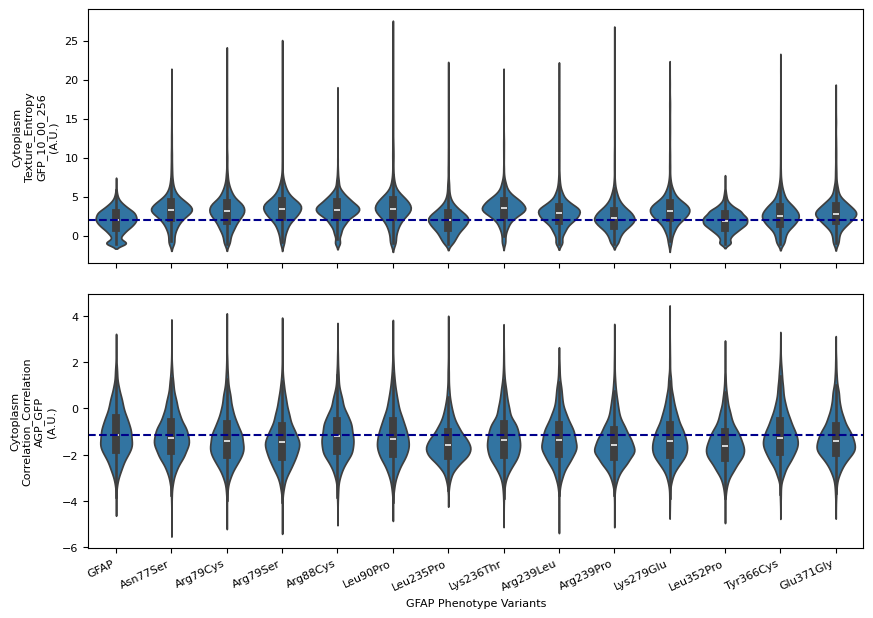

In [63]:
feats_to_plot = ["Cytoplasm_Texture_Entropy_GFP_10_00_256", "Cytoplasm_Correlation_Correlation_AGP_GFP"]
df_temp = profiles.filter(
    pl.col("Metadata_gene_allele").is_in(gfap_alleles),
)

fig, axes = plt.subplots(2,1,figsize=(10,7),sharex=True)
for i, feat in enumerate(feats_to_plot):
    sns.violinplot(
        data=df_temp.to_pandas(),
        x="Metadata_gene_allele",
        y=feat,
        order=gfap_alleles,
        ax=axes[i]
    )
    axes[i].set_ylabel(f"{feat.split('_')[0]}\n{'_'.join(feat.split('_')[1:3])}\n{'_'.join(feat.split('_')[3:])}\n(A.U.)", fontsize=8)
    ref_median = df_temp.filter(pl.col("Metadata_gene_allele")=="GFAP")[feat].median()
    axes[i].axhline(ref_median, color='darkblue', linestyle='--', linewidth=1.5)
    axes[i].set_yticklabels(axes[i].get_yticklabels(), fontsize=8)

axes[-1].set_xlabel("GFAP Phenotype Variants", fontsize=8)
axes[-1].set_xticklabels([x.get_text().split('_')[-1] for x in axes[-1].get_xticklabels()], fontsize=8, rotation=25, ha='right')
plt.subplots_adjust(hspace=0.12)
plt.show()

In [64]:
with pl.Config(set_tbl_rows=20):
    print(gfap_alleles_df["gene_variant", "img_pheno_score","clinvar_clnsig_clean_pp_strict"].sort("img_pheno_score", descending=True))#.to_list()
    print(
        imaging_summary_clinvar.filter(
            pl.col("Gene")=="GFAP",
            ~pl.col("gene_variant").is_in(gfap_alleles_df["gene_variant"])
        )["gene_variant", "img_pheno_score", "clinvar_clnsig_clean_pp_strict"].sort("img_pheno_score", descending=True)
    )

shape: (13, 3)
┌────────────────┬─────────────────┬────────────────────────────────┐
│ gene_variant   ┆ img_pheno_score ┆ clinvar_clnsig_clean_pp_strict │
│ ---            ┆ ---             ┆ ---                            │
│ str            ┆ f64             ┆ str                            │
╞════════════════╪═════════════════╪════════════════════════════════╡
│ GFAP_Arg88Cys  ┆ 0.977091        ┆ Pathogenic                     │
│ GFAP_Arg79Ser  ┆ 0.973553        ┆ VUS                            │
│ GFAP_Lys236Thr ┆ 0.973388        ┆ Others                         │
│ GFAP_Asn77Ser  ┆ 0.968469        ┆ Pathogenic                     │
│ GFAP_Leu352Pro ┆ 0.967293        ┆ Pathogenic                     │
│ GFAP_Leu90Pro  ┆ 0.962373        ┆ Others                         │
│ GFAP_Glu371Gly ┆ 0.958287        ┆ Others                         │
│ GFAP_Leu235Pro ┆ 0.958086        ┆ Others                         │
│ GFAP_Arg79Cys  ┆ 0.955883        ┆ Pathogenic                     │
│ GFA

In [66]:
# def plot_single_allele(allele_cell_profiles, num_r, num_col, channels=["GFP"]):
#     fig, axes = plt.subplots(num_r, num_col, figsize=(num_r*3, num_col*3))
#     cell_idx = 0
#     for idx in range(num_r*num_col):
#         # Keep loading cells until we find one with std >= 50
#         var_crops = load_multichannel_cell_crops(
#             allele_cell_profiles[cell_idx],
#             channels,
#             imgs_dir=TIFF_IMGS_DIR,
#             method='fixed',
#             crop_size=256,
#         )
#         # Skip cells with low std (likely background/empty)
#         while np.std(var_crops["GFP"]) < 1000:
#             cell_idx += 1  # Move to next cell FIRST
#             if cell_idx >= len(allele_cell_profiles):
#                 print(f"Warning: Ran out of cells")
#                 break
#             var_crops = load_multichannel_cell_crops(
#                 allele_cell_profiles[cell_idx],
#                 channels,
#                 imgs_dir=TIFF_IMGS_DIR,
#                 method='fixed',
#                 crop_size=256,
#             )
#         viz_cell_single_channel(
#             var_crops[channels[0]],
#             channel=channels[0],
#             ax=axes[idx//num_col, idx%num_col],
#             axis_off=True,
#             percentile_low=2.5,
#             percentile_high=97.5,
#             # title=f'A{idx+1}' if j % 5 == 0 else None
#         )
#         cell_idx += 1  # Move to next cell for the next iteration of j
#     plt.tight_layout()
#     plt.subplots_adjust(wspace=0.1, hspace=-.94)
#     plt.show()

# plot_single_allele(
#     select_cells_percentile_random(
#         gfap_allele_cells["GFAP"],
#         feature="Cytoplasm_Texture_Entropy_GFP_10_00_256",
#         percentile_bins=[(40, 60)],  # Top 20% of feature values
#         n_per_bin=1000,
#         seed=0
#     ),#.sort("Abs_dev", descending=True),
#     num_r=5, num_col=10
# )

# plot_single_allele(
#     select_cells_percentile_random(
#         gfap_allele_cells["GFAP_Arg88Cys"],
#         feature="Cytoplasm_Texture_Entropy_GFP_10_00_256",
#         percentile_bins=[(40, 60)],  # Top 20% of feature values
#         n_per_bin=1000,
#         seed=0
#     ),#.sort("Abs_dev", descending=True),
#     num_r=5, num_col=10
# )

# plot_single_allele(
#     select_cells_percentile_random(
#         gfap_allele_cells["GFAP_Leu235Pro"],
#         feature="Cytoplasm_Correlation_Correlation_AGP_GFP",
#         percentile_bins=[(40, 60)],  # Top 20% of feature values
#         n_per_bin=1000,
#         seed=4
#     ),#.sort("Abs_dev", descending=True),
#     num_r=5, num_col=10
# )

In [51]:
# Create figure: 2 rows (VAR on top, REF on bottom) x 20 columns (one per cell)
# plot_multi_cell_plots(gfap_allele_cells)

### 2.2 MLH1

In [101]:
# allele_cell_profiles = select_cells_percentile_random(
#     mlh1_allele_cells["MLH1_Leu653Pro"],
#     feature="Cells_AreaShape_Area",
#     percentile_bins=[(40, 60)],  # Top 20% of feature values
#     n_per_bin=1000,
#     seed=42
# )

# fig, axes = plt.subplots(1, 5)
# # print(len(allele_cell_profiles))
# cell_idx = 0
# # print(len(allele_cell_profiles))
# for j in range(5):
#     # Keep loading cells until we find one with std >= 50
#     var_crops = load_multichannel_cell_crops(
#         allele_cell_profiles[cell_idx],
#         channels,
#         imgs_dir=TIFF_IMGS_DIR,
#         method='fixed',
#         crop_size=128,
#     )
#     # print(var_crops)
#     # Skip cells with low std (likely background/empty)
#     while np.std(var_crops["GFP"]) < 50:
#         cell_idx += 1  # Move to next cell FIRST
#         if cell_idx >= len(allele_cell_profiles):
#             print(f"Warning: Ran out of cells for {allele_cells[0]}")
#             break
#         var_crops = load_multichannel_cell_crops(
#             allele_cell_profiles[cell_idx],
#             channels,
#             imgs_dir=TIFF_IMGS_DIR,
#             method='fixed',
#             crop_size=128,
#         )
#     viz_cell_single_channel(
#         var_crops[channels[0]],
#         channel=channels[0],
#         ax=axes[j],
#         axis_off=True,
#         percentile_low=1.0,
#         percentile_high=99.0,
#         # title=f'A{idx+1}' if j % 5 == 0 else None
#     )
#     cell_idx += 1  # Move to next cell FIRST
# plt.show()

In [54]:
mlh1_allele_cluster_df = cluster_result_df.with_columns(
    pl.col("Metadata_gene_allele").str.split("_").list.get(0).alias("Gene")
).filter(
    pl.col("Gene")=="MLH1"
).sort("Metadata_img_pheno_score", descending=True).select(
    "Metadata_gene_allele","Metadata_img_pheno_score", "Metadata_cluster"
).unique("Metadata_cluster")
mlh1_allele_cluster_df

Metadata_gene_allele,Metadata_img_pheno_score,Metadata_cluster
str,f64,i64
"""MLH1_Val185Gly""",0.994092,7
"""MLH1_Ser295Thr""",0.982091,3
"""MLH1_Ser44Phe""",0.997614,2
"""MLH1_Lys670Arg""",0.943798,1
"""MLH1_Leu653Pro""",0.973989,6


In [1]:
# mlh1_allele_cluster_df = cluster_result_df.with_columns(
#     pl.col("Metadata_gene_allele").str.split("_").list.get(0).alias("Gene")
# ).filter(
#     pl.col("Gene")=="MLH1"
# ).sort("Metadata_img_pheno_score", descending=True).select(
#     "Metadata_gene_allele","Metadata_img_pheno_score", "Metadata_cluster"
# ).unique("Metadata_cluster")["Metadata_gene_allele"].to_list()
# # mlh1_alleles = mlh1_allele_cluster_df["gene_allele"].to_list()
# display(mlh1_allele_cluster_df)

# mlh1_allele_group1_cells = {
#     allele: filter_by_quality_metrics(
#         filter_cells_by_metadata(profiles, allele=allele),
#         min_edge_dist=50
#     )
#     for allele in ["MLH1"]+['MLH1_Val185Gly','MLH1_Lys670Arg','MLH1_Ser44Phe']
# }

# mlh1_allele_group2_cells = {
#     allele: filter_by_quality_metrics(
#         filter_cells_by_metadata(profiles, allele=allele),
#         min_edge_dist=50
#     )
#     for allele in ["MLH1"]+['MLH1_Leu653Pro','MLH1_Ser295Thr']
# }

# plot_multi_cell_plots(mlh1_allele_group1_cells, feat="Cells_Correlation_Correlation_DNA_GFP", crop_size=256, n_cells=5, seed=10)

In [2]:
# plot_multi_cell_plots(mlh1_allele_group2_cells, feat="Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256", crop_size=256, n_cells=5, seed=42)

### 2.3 LITAF

shape: (11, 2)
┌──────────────────────┬──────────────────────────┐
│ Metadata_gene_allele ┆ Metadata_img_pheno_score │
│ ---                  ┆ ---                      │
│ str                  ┆ f64                      │
╞══════════════════════╪══════════════════════════╡
│ LITAF_Trp116Gly      ┆ 0.977011                 │
│ LITAF_Pro135Thr      ┆ 0.960307                 │
│ LITAF_Leu122Val      ┆ 0.975081                 │
│ LITAF_Ile92Val       ┆ 0.996021                 │
│ LITAF_Pro135Ser      ┆ 0.962327                 │
│ LITAF_Pro84Leu       ┆ 0.977909                 │
│ LITAF_Ser118Pro      ┆ 0.978597                 │
│ LITAF_Val144Met      ┆ 0.977088                 │
│ LITAF_Ala129Val      ┆ 0.934202                 │
│ LITAF_Pro135Arg      ┆ 0.971816                 │
│ LITAF_Phe136Leu      ┆ 0.963826                 │
└──────────────────────┴──────────────────────────┘


<Figure size 640x480 with 0 Axes>

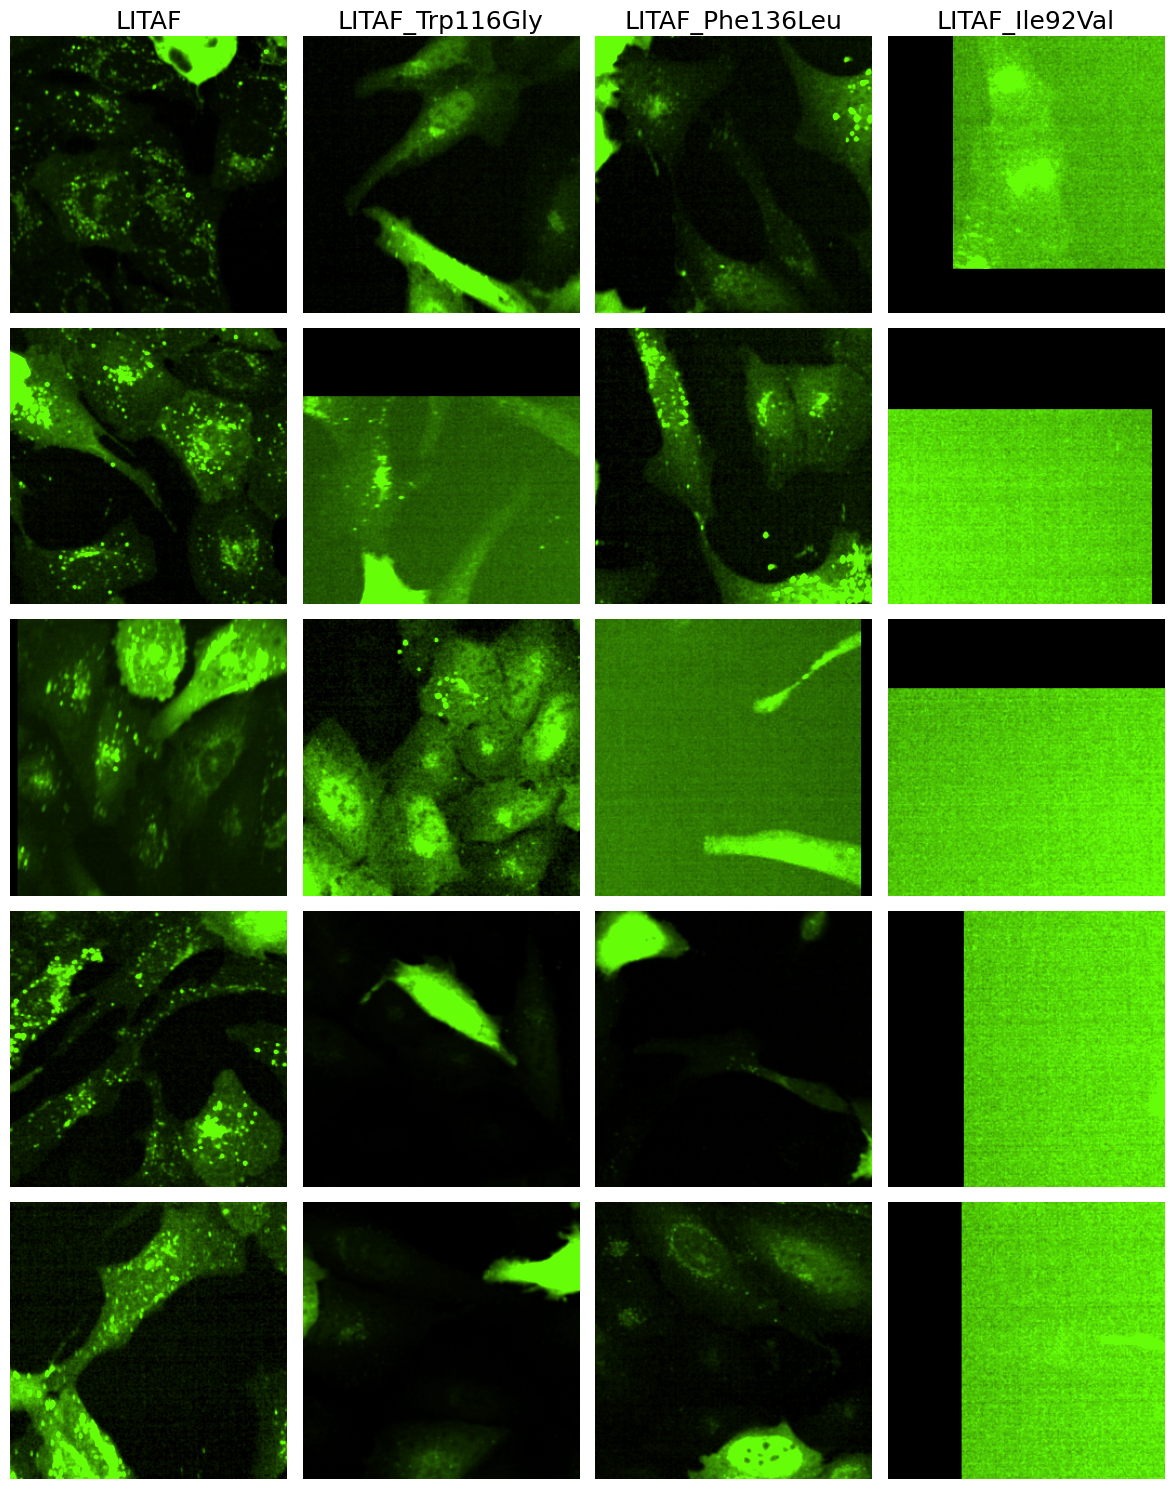

In [7]:
litaf1_allele_cluster_df = cluster_result_df.filter(
    pl.col("Metadata_gene_allele").str.contains("LITAF")
)#.unique("cluster").sort("cluster")
with pl.Config(set_tbl_rows=1000):
    print(litaf1_allele_cluster_df.select("Metadata_gene_allele","Metadata_img_pheno_score"))

# litaf1_allele_cluster_df = litaf1_allele_cluster_df["gene_allele"].to_list()

litaf1_allele_cells = {
    allele: filter_by_quality_metrics(
        filter_cells_by_metadata(profiles, allele=allele),
        min_edge_dist=50
    )
    for allele in ["LITAF"]+["LITAF_Trp116Gly", "LITAF_Phe136Leu", "LITAF_Ile92Val"]
}
# mlh1_allele_cells.pop('MLH1_Ser295Thr', None)
# mlh1_allele_cells.pop('MLH1_Leu653Pro', None)
# mlh1_allele_cells.pop('MLH1_Gln701His', None)

plot_multi_cell_plots(litaf1_allele_cells, crop_size=256, n_cells=5, seed=42)

In [80]:
with pl.Config(set_tbl_rows=1000):
    imaging_summary_clinvar.filter(
        pl.col("gene_variant").str.contains("LITAF")
    ).select("gene_variant","img_pheno_score","img_pheno_hit")

## 3. Cluster Analyses

In [40]:
cluster_alleles = cluster_analysis_df.filter(
    pl.col("cluster")==4
)["gene_allele"].to_list()

cluster_alleles_keys = cluster_result_df.filter(
    pl.col("Metadata_cluster")==4
).sort("Metadata_img_pheno_score", descending=True).select(
    "Metadata_gene_allele","Metadata_img_pheno_score"
).with_columns(
    pl.col("Metadata_gene_allele").str.split("_").list.get(0).alias("Gene")
).unique("Gene")["Metadata_gene_allele"].to_list()


cluster1_alleles = sorted(set([al.split('_')[0] for al in cluster_alleles_keys]+cluster_alleles_keys))
batch_allele_cells = {
    allele: filter_by_quality_metrics(
        filter_cells_by_metadata(profiles, allele=allele),
        min_edge_dist=200
    )
     for allele in cluster1_alleles[:10]+["PLP1_Trp128Arg"]
}

In [4]:
# plot_multi_cell_plots(batch_allele_cells, feat="Cells_Correlation_Correlation_GFP_Mito", crop_size=256, n_cells=5, seed=10)

In [34]:
# # Create figure: 2 rows (VAR on top, REF on bottom) x 20 columns (one per cell)
# n_cells = 5
# fig, axes = plt.subplots(len(batch_allele_cells.items()), n_cells, figsize=(n_cells*3, len(batch_allele_cells.items())*3))
# channels = ["GFP"]

# for idx, allele_cells in enumerate(batch_allele_cells.items()):
#     print(allele_cells[0])
#     allele_cell_profiles = select_cells_percentile_random(
#         batch_allele_cells[allele_cells[0]],
#         feature="Cells_AreaShape_Area",
#         percentile_bins=[(40, 60)],  # Top 20% of feature values
#         n_per_bin=n_cells*5,
#         seed=42
#     )
#     cell_idx = 0
#     for j in range(n_cells):
#         # Keep loading cells until we find one with std >= 50
#         var_crops = load_multichannel_cell_crops(
#             allele_cell_profiles[cell_idx],
#             channels,
#             imgs_dir=TIFF_IMGS_DIR,
#             method='fixed',
#             crop_size=128,
#         )
#         # Skip cells with low std (likely background/empty)
#         while np.std(var_crops["GFP"]) < 100:
#             cell_idx += 1  # Move to next cell FIRST
#             if cell_idx >= len(allele_cell_profiles):
#                 print(f"Warning: Ran out of cells for {allele_cells[0]}")
#                 break
#             var_crops = load_multichannel_cell_crops(
#                 allele_cell_profiles[cell_idx],
#                 channels,
#                 imgs_dir=TIFF_IMGS_DIR,
#                 method='fixed',
#                 crop_size=128,
#             )
#         viz_cell_single_channel(
#             var_crops['GFP'],
#             channel='GFP',
#             ax=axes[idx, j],
#             axis_off=True,
#             percentile_low=1.0,
#             percentile_high=99.0,
#             title=f'A{j+1}' if j % 5 == 0 else None
#         )
#         cell_idx += 1  # Move to next cell for the next iteration of j

#     axes[idx, 0].text(-0.15, 0.5, allele_cells[0],
#                     transform=axes[idx, 0].transAxes,
#                     fontsize=14, fontweight='bold',
#                     rotation=90, va='center', ha='right')

# plt.tight_layout()
# plt.subplots_adjust(wspace=0)
# plt.show()